# Medical Insurance Premium Prediction
### Using Linear Regression

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## Step 1: Dataset Load

In [2]:
df = pd.read_csv('insurance.csv')
print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## Step 2: Data Preprocessing

In [3]:
# Encode categorical columns into numeric format
le = LabelEncoder()
df['sex'] = le.fit_transform(df['sex'])           # female=0, male=1
df['smoker'] = le.fit_transform(df['smoker'])      # no=0, yes=1
df['region'] = le.fit_transform(df['region'])      # encoded 0-3

# Separate features (X) and target variable (y)
X = df.drop('charges', axis=1)
y = df['charges']

print("Features:", list(X.columns))
print("Target: charges")

Features: ['age', 'sex', 'bmi', 'children', 'smoker', 'region']
Target: charges


## Step 3: Train-Test Split (80/20)

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Training: {X_train.shape[0]} samples")
print(f"Testing:  {X_test.shape[0]} samples")

Training: 1070 samples
Testing:  268 samples


## Step 4: Model Train

In [5]:
model = LinearRegression()
model.fit(X_train, y_train)
print("Model Trained Successfully!")

Model Trained Successfully!


## Step 5: Model Performance

In [6]:
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MAE  (Mean Absolute Error): ${mae:,.2f}")
print(f"RMSE (Root Mean Sq Error):  ${rmse:,.2f}")
print(f"R2 Score: {r2:.4f} ({r2*100:.1f}%)")

MAE  (Mean Absolute Error): $4,186.51
RMSE (Root Mean Sq Error):  $5,799.59
R2 Score: 0.7833 (78.3%)


## Step 6: Actual vs Predicted Plot

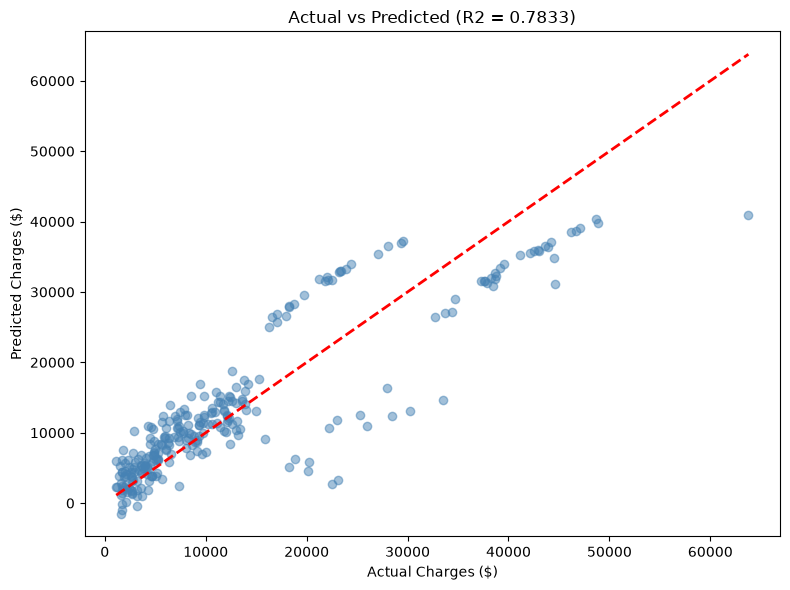

In [7]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.5, color='steelblue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', linewidth=2)
plt.xlabel('Actual Charges ($)')
plt.ylabel('Predicted Charges ($)')
plt.title(f'Actual vs Predicted (R2 = {r2:.4f})')
plt.tight_layout()
plt.show()